In [42]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [43]:
# change this path if the CSV is stored in another folder
file_path = "global_pharmacy_sales_data.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print(df.head())

Dataset shape: (177990, 14)

Columns:
['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
         date  year  month  day         region    country category  \
0  2025-10-12  2025     10   12    Middle East        UAE  Chronic   
1  2020-09-15  2020      9   15     South Asia      India  Chronic   
2  2020-02-26  2020      2   26    Middle East        UAE  Vitamin   
3  2025-11-09  2025     11    9     South Asia  Sri Lanka  Chronic   
4  2022-04-04  2022      4    4  South America  Argentina  Chronic   

     medicine age_group  units_sold  unit_price  stock_level  \
0  Amlodipine      0-12         328       45.38         4774   
1  Amlodipine     26-45         371       75.49         4584   
2   Vitamin C      0-12         948       22.51         3934   
3  Amlodipine      0-12         275       63.29         4544   
4  Amlodipine     26-45         563       44.28 

In [44]:
#clean data and create the target
# make sure the required columns are available
required_cols = ["units_sold", "unit_price"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Dataset is missing required columns: {missing_cols}")

# convert numeric target inputs safely
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# remove rows that cannot be used to calculate sales value
df = df.dropna(subset=["units_sold", "unit_price"]).copy()

# create the target value
df["sales_value"] = df["units_sold"] * df["unit_price"]

# use date ordering when a date column is available
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)

print("Prepared dataset shape:", df.shape)
display(df.head())

Prepared dataset shape: (177990, 15)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag,sales_value
0,2020-01-01,2020,1,1,Africa,Nigeria,Cough_Cold,Cough Syrup,65+,687,8.71,4287,113,1,5983.77
1,2020-01-01,2020,1,1,East Asia,South Korea,Chronic,Amlodipine,13-25,684,7.12,4481,408,1,4870.08
2,2020-01-01,2020,1,1,South America,Argentina,Chronic,Amlodipine,46-65,967,21.75,3964,498,1,21032.25
3,2020-01-01,2020,1,1,East Asia,China,Antibiotic,Azithromycin,26-45,545,5.22,4525,450,1,2844.90
4,2020-01-01,2020,1,1,North America,Canada,Antipyretic,Paracetamol,13-25,497,12.70,4598,560,1,6311.90


In [45]:
#select features and target
# remove target and its source columns to avoid target leakage
exclude_cols = ["sales_value", "units_sold", "unit_price"]

# date itself is not passed to the models; year/month/day columns can still be used
if "date" in df.columns:
    exclude_cols.append("date")

X = df.drop(columns=exclude_cols, errors="ignore").copy()
y = df["sales_value"].copy()

# remove columns that contain only one value because they cannot help split data
constant_cols = [col for col in X.columns if X[col].nunique(dropna=False) <= 1]
if constant_cols:
    X = X.drop(columns=constant_cols)
    print("Removed constant columns:", constant_cols)

# identify numerical and categorical columns
num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Input feature count:", X.shape[1])
print("Numerical features:", num_cols)
print("Categorical features:", cat_cols)
print("Target: sales_value")

Input feature count: 11
Numerical features: ['year', 'month', 'day', 'stock_level', 'expiry_days_remaining', 'covid_flag']
Categorical features: ['region', 'country', 'category', 'medicine', 'age_group']
Target: sales_value


In [46]:
#split training and test data
# use earlier rows for training and later rows for final testing
split = int(len(X) * 0.80)

if split < 10 or len(X) - split < 2:
    raise ValueError("The dataset is too small for an 80/20 train-test split.")

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()
y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

if "date" in df.columns:
    print("Training ends:", df["date"].iloc[split - 1])
    print("Testing starts:", df["date"].iloc[split])

Training records: 142392
Testing records: 35598
Training ends: 2024-10-19 00:00:00
Testing starts: 2024-10-19 00:00:00


In [ ]:
#build preprocessing pipeline
# fill missing numerical values with the median
num_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="median"))
])

# fill missing categories and one-hot encode them
cat_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

# apply the correct preparation to each column type
transformers = []
if num_cols:
    transformers.append(("num", num_pipe, num_cols))
if cat_cols:
    transformers.append(("cat", cat_pipe, cat_cols))

preprocessor = ColumnTransformer(transformers=transformers)

Preprocessing pipeline created.


In [48]:
#train models and compare test performance
# store trained pipelines and evaluation results
best_models = {}
model_results = []

for name, model in models.items():
    print("\nTraining:", name)
    start = time.time()

    # keep preprocessing and model together to avoid data leakage
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    # calculate common regression metrics
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    best_models[name] = pipe
    model_results.append({
        "Model": name,
        "Test RMSE": rmse,
        "Test MAE": mae,
        "Test R2": r2,
        "Training Time (seconds)": round(time.time() - start, 2)
    })

    print("Test RMSE:", round(rmse, 3))
    print("Test MAE:", round(mae, 3))
    print("Test R2:", round(r2, 4))

model_comparison = pd.DataFrame(model_results).sort_values("Test RMSE")
display(model_comparison)


Training: LightGBM
Test RMSE: 13164.693
Test MAE: 9200.341
Test R2: 0.4587

Training: CatBoost
Test RMSE: 12895.739
Test MAE: 9175.335
Test R2: 0.4806

Training: XGBoost
Test RMSE: 13128.56
Test MAE: 9193.354
Test R2: 0.4616


,Model,Test RMSE,Test MAE,Test R2,Training Time (seconds)
1,CatBoost,12895.739112,9175.334721,0.480564,2.64
2,XGBoost,13128.560144,9193.354254,0.461639,1.14
0,LightGBM,13164.693271,9200.341229,0.458672,1.17


In [50]:
#calculate permutation importance
# make sure Cell 9 has been run
if "best_models" not in globals() or not best_models:
    raise NameError("Run Cell 9 first so best_models contains trained models.")

# use a sample of the test data to reduce calculation time
n_sample = min(5000, len(X_test))
X_perm = X_test.sample(n=n_sample, random_state=42)
y_perm = y_test.loc[X_perm.index]

perm_results = []

for name, model in best_models.items():
    print("Calculating permutation importance:", name)

    perm = permutation_importance(
        model,
        X_perm,
        y_perm,
        scoring="neg_root_mean_squared_error",
        n_repeats=5,
        random_state=42,
        n_jobs=1
    )

    temp = pd.DataFrame({
        "Feature": X_perm.columns,
        "Importance": perm.importances_mean,
        "Std": perm.importances_std,
        "Model": name
    })
    perm_results.append(temp)

perm_df = pd.concat(perm_results, ignore_index=True)

for name in best_models:
    print("\nTop 10 permutation features:", name)
    display(
        perm_df[perm_df["Model"] == name]
        .sort_values("Importance", ascending=False)
        .head(10)
        .round(4)
    )


Calculating permutation importance: LightGBM
Calculating permutation importance: CatBoost
Calculating permutation importance: XGBoost

Top 10 permutation features: LightGBM


,Feature,Importance,Std,Model
8,stock_level,7870.3814,122.2128,LightGBM
1,month,545.8948,146.9420,LightGBM
9,expiry_days_remaining,98.7076,100.4318,LightGBM
2,day,31.2362,76.9833,LightGBM
0,year,0.0000,0.0000,LightGBM
10,covid_flag,0.0000,0.0000,LightGBM
5,category,-0.7351,26.3452,LightGBM
3,region,-2.6157,31.7246,LightGBM
6,medicine,-34.6050,25.7121,LightGBM
7,age_group,-53.2694,27.5227,LightGBM



Top 10 permutation features: CatBoost


,Feature,Importance,Std,Model
19,stock_level,7404.2034,102.8408,CatBoost
12,month,482.0317,131.4700,CatBoost
16,category,24.2401,9.9828,CatBoost
20,expiry_days_remaining,23.6479,41.4524,CatBoost
18,age_group,16.9976,44.6336,CatBoost
11,year,0.0000,0.0000,CatBoost
21,covid_flag,0.0000,0.0000,CatBoost
14,region,-0.7022,24.5349,CatBoost
13,day,-7.4512,60.2049,CatBoost
17,medicine,-20.3756,20.9869,CatBoost



Top 10 permutation features: XGBoost


,Feature,Importance,Std,Model
30,stock_level,8095.8716,159.6518,XGBoost
23,month,590.6629,153.3846,XGBoost
31,expiry_days_remaining,69.8762,73.2386,XGBoost
24,day,50.2610,91.9136,XGBoost
22,year,0.0000,0.0000,XGBoost
32,covid_flag,0.0000,0.0000,XGBoost
27,category,-0.4905,28.9595,XGBoost
29,age_group,-6.0551,45.8676,XGBoost
25,region,-34.0547,39.0490,XGBoost
28,medicine,-61.2174,69.1122,XGBoost


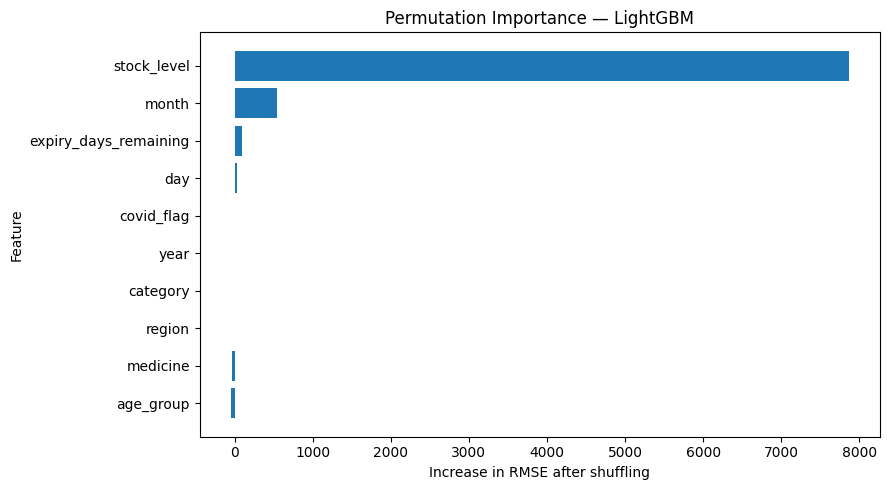

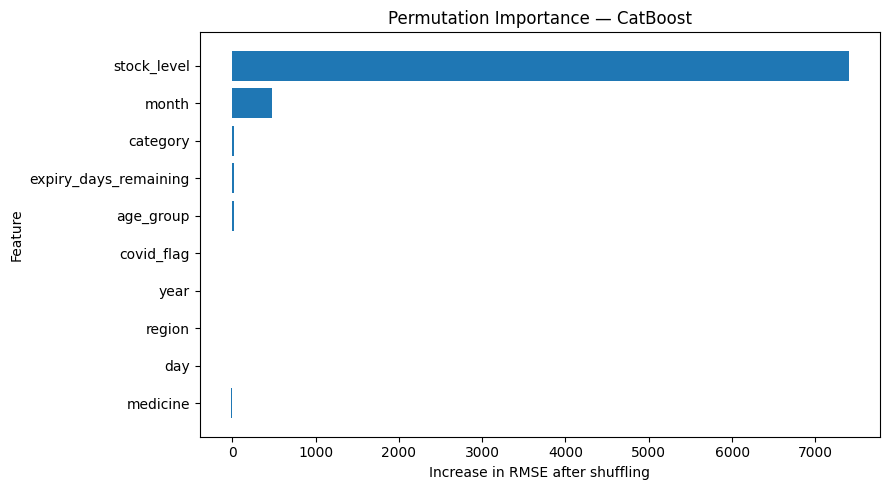

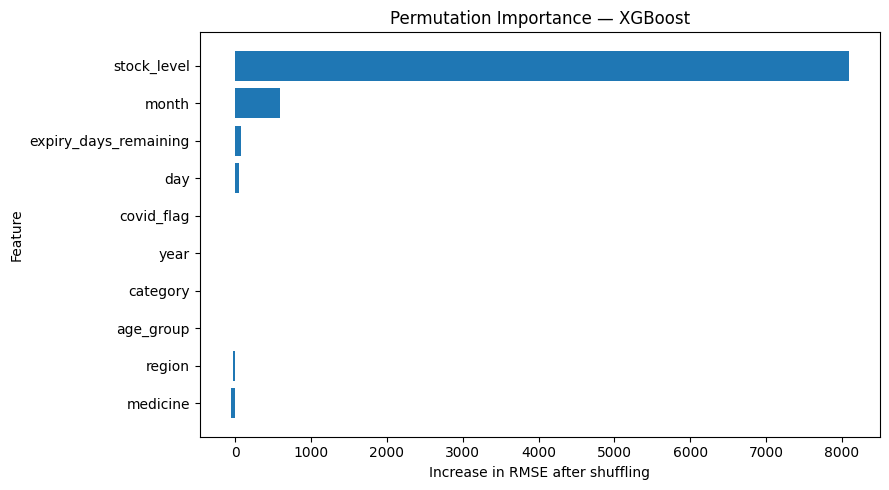

In [51]:
# plot the 10 most important original features for each model
for name in best_models:
    top = (
        perm_df[perm_df["Model"] == name]
        .sort_values("Importance")
        .tail(10)
    )

    plt.figure(figsize=(9, 5))
    plt.barh(top["Feature"], top["Importance"])
    plt.title(f"Permutation Importance — {name}")
    plt.xlabel("Increase in RMSE after shuffling")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

In [53]:
#calculate SHAP values
# use a small test sample so SHAP calculations remain manageable
X_shap = X_test.sample(n=min(300, len(X_test)), random_state=42)
shap_results = {}

for name, pipe in best_models.items():
    print("Calculating SHAP values:", name)

    # get the fitted preprocessing step and tree model
    prep = pipe.named_steps["prep"]
    tree_model = pipe.named_steps["model"]

    # transform the sample using training-fitted preprocessing
    X_encoded = prep.transform(X_shap)

    # SHAP tree explainers work most simply with a dense DataFrame
    if hasattr(X_encoded, "toarray"):
        X_encoded = X_encoded.toarray()

    feature_names = prep.get_feature_names_out()
    X_encoded = pd.DataFrame(
        X_encoded,
        columns=feature_names,
        index=X_shap.index
    )

    # explain the model's predictions using tree SHAP
    explainer = shap.TreeExplainer(tree_model)
    shap_values = explainer.shap_values(X_encoded)

    # support SHAP outputs that may include an extra output dimension
    if isinstance(shap_values, list):
        shap_values = shap_values[0]
    if np.asarray(shap_values).ndim == 3:
        shap_values = np.asarray(shap_values)[:, :, 0]

    shap_results[name] = {
        "values": np.asarray(shap_values),
        "data": X_encoded
    }

    print("SHAP completed:", name)

Calculating SHAP values: LightGBM
SHAP completed: LightGBM
Calculating SHAP values: CatBoost
SHAP completed: CatBoost
Calculating SHAP values: XGBoost
SHAP completed: XGBoost


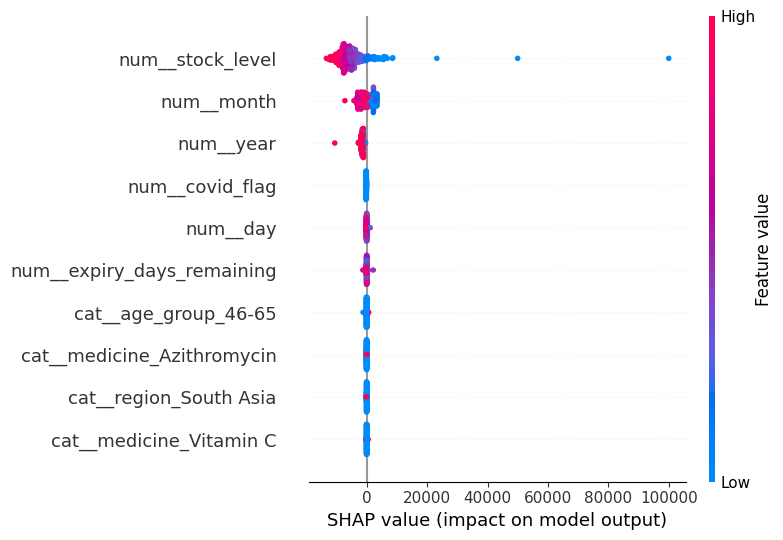

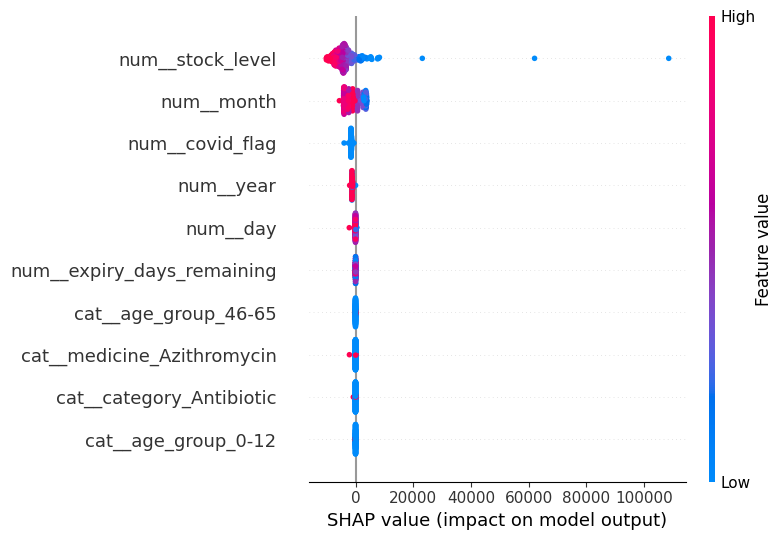

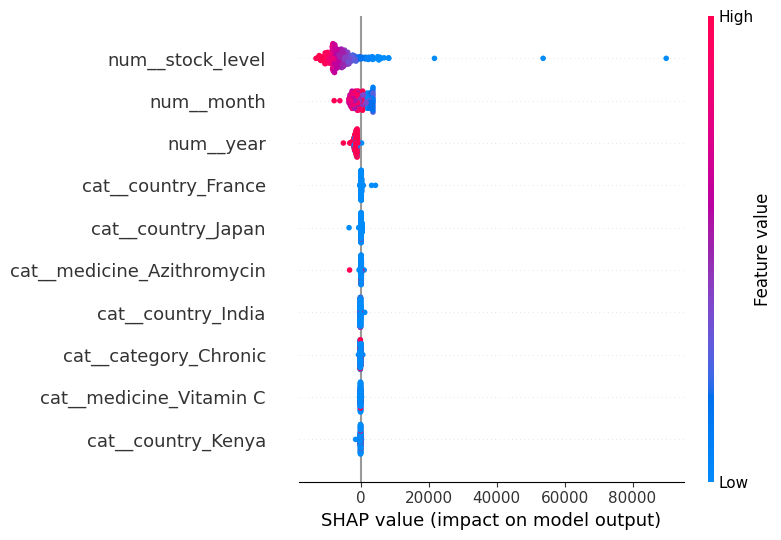

In [54]:
#plot SHAP beeswarm contributions
# beeswarm plots show whether feature contributions are positive or negative
for name, result in shap_results.items():
    shap.summary_plot(
        result["values"],
        result["data"],
        max_display=10,
        show=True
    )

In [55]:
# lightGBM and XGBoost expose gain-based importance.
# catBoost uses PredictionValuesChange, which is a different native metric.
gain_results = []

for name, pipe in best_models.items():
    tree_model = pipe.named_steps["model"]
    feature_names = pipe.named_steps["prep"].get_feature_names_out()

    if name == "LightGBM":
        scores = tree_model.booster_.feature_importance(importance_type="gain")
        metric = "Gain"

    elif name == "XGBoost":
        score_dict = tree_model.get_booster().get_score(importance_type="gain")
        scores = [score_dict.get(f"f{i}", 0.0) for i in range(len(feature_names))]
        metric = "Gain"

    else:
        scores = tree_model.get_feature_importance(type="PredictionValuesChange")
        metric = "PredictionValuesChange"

    temp = pd.DataFrame({
        "Feature": feature_names,
        "Importance": scores,
        "Model": name,
        "Metric": metric
    })
    gain_results.append(temp)

gain_df = pd.concat(gain_results, ignore_index=True)

for name in best_models:
    print("\nTop 10 tree-based features:", name)
    display(
        gain_df[gain_df["Model"] == name]
        .sort_values("Importance", ascending=False)
        .head(10)
        .round(4)
    )


Top 10 tree-based features: LightGBM


,Feature,Importance,Model,Metric
3,num__stock_level,4.807455e+14,LightGBM,Gain
4,num__expiry_days_remaining,1.835987e+13,LightGBM,Gain
1,num__month,1.466920e+13,LightGBM,Gain
2,num__day,1.279683e+13,LightGBM,Gain
0,num__year,8.586459e+12,LightGBM,Gain
5,num__covid_flag,1.042406e+12,LightGBM,Gain
49,cat__age_group_13-25,8.496118e+11,LightGBM,Gain
48,cat__age_group_0-12,6.275054e+11,LightGBM,Gain
36,cat__category_Cough_Cold,5.943561e+11,LightGBM,Gain
50,cat__age_group_26-45,5.600826e+11,LightGBM,Gain



Top 10 tree-based features: CatBoost


,Feature,Importance,Model,Metric
56,num__stock_level,62.9678,CatBoost,PredictionValuesChange
54,num__month,12.1159,CatBoost,PredictionValuesChange
58,num__covid_flag,4.9888,CatBoost,PredictionValuesChange
53,num__year,3.9414,CatBoost,PredictionValuesChange
57,num__expiry_days_remaining,3.8472,CatBoost,PredictionValuesChange
55,num__day,3.5995,CatBoost,PredictionValuesChange
103,cat__age_group_26-45,1.1079,CatBoost,PredictionValuesChange
76,cat__country_Japan,0.5362,CatBoost,PredictionValuesChange
95,cat__medicine_Cough Syrup,0.4968,CatBoost,PredictionValuesChange
60,cat__region_East Asia,0.4800,CatBoost,PredictionValuesChange



Top 10 tree-based features: XGBoost


,Feature,Importance,Model,Metric
109,num__stock_level,2.958469e+11,XGBoost,Gain
156,cat__age_group_26-45,3.188799e+10,XGBoost,Gain
147,cat__medicine_Cetirizine,2.520393e+10,XGBoost,Gain
125,cat__country_China,2.330781e+10,XGBoost,Gain
142,cat__category_Cough_Cold,2.206329e+10,XGBoost,Gain
117,cat__region_Oceania,2.180449e+10,XGBoost,Gain
120,cat__country_Argentina,1.996746e+10,XGBoost,Gain
157,cat__age_group_46-65,1.974813e+10,XGBoost,Gain
155,cat__age_group_13-25,1.963928e+10,XGBoost,Gain
106,num__year,1.961163e+10,XGBoost,Gain


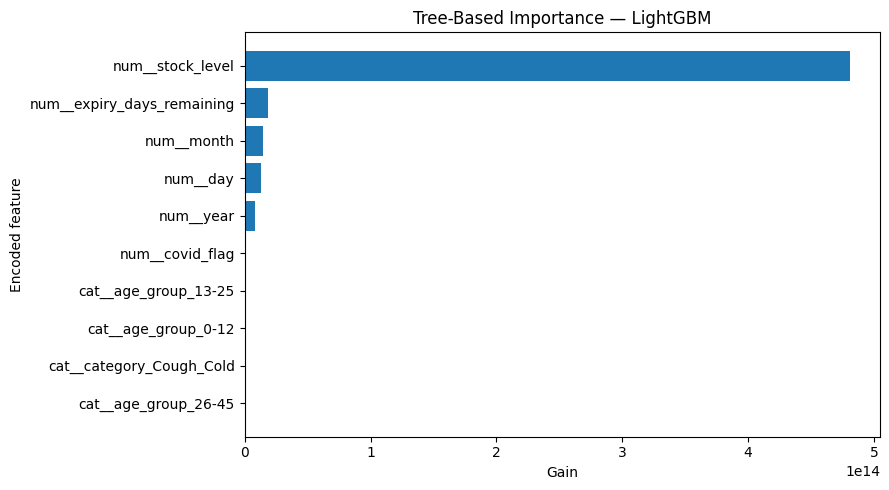

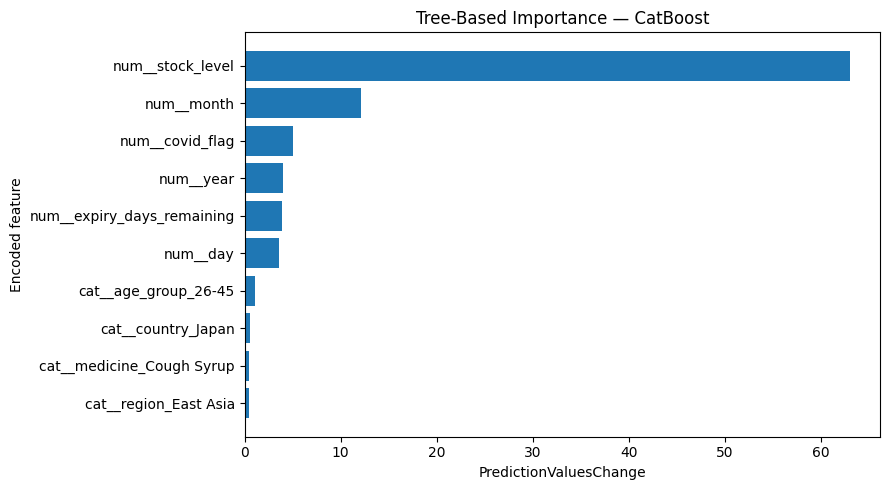

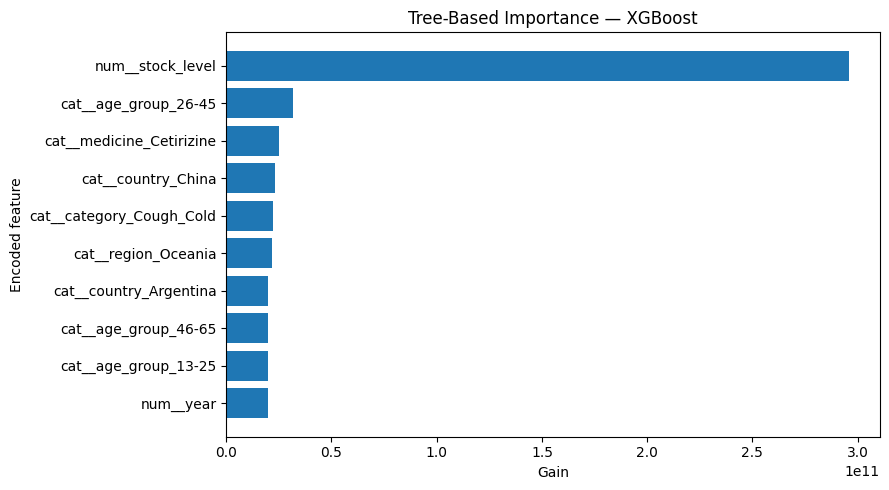

In [56]:
# visualize the top 10 features used by each tree model
for name in best_models:
    top = (
        gain_df[gain_df["Model"] == name]
        .sort_values("Importance")
        .tail(10)
    )

    plt.figure(figsize=(9, 5))
    plt.barh(top["Feature"], top["Importance"])
    plt.title(f"Tree-Based Importance — {name}")
    plt.xlabel(top["Metric"].iloc[0])
    plt.ylabel("Encoded feature")
    plt.tight_layout()
    plt.show()

In [ ]:
#compare rankings across all methods
# calculate mean absolute SHAP importance for every encoded feature
shap_rows = []

for name, result in shap_results.items():
    mean_shap = np.abs(result["values"]).mean(axis=0)

    shap_rows.append(pd.DataFrame({
        "Feature": result["data"].columns,
        "SHAP Importance": mean_shap,
        "Model": name
    }))

shap_df = pd.concat(shap_rows, ignore_index=True)

# print each method's top features side by side by model
for name in best_models:
    p = (
        perm_df[perm_df["Model"] == name]
        .sort_values("Importance", ascending=False)
        .head(10)["Feature"].tolist()
    )

    s = (
        shap_df[shap_df["Model"] == name]
        .sort_values("SHAP Importance", ascending=False)
        .head(10)["Feature"].tolist()
    )

    g = (
        gain_df[gain_df["Model"] == name]
        .sort_values("Importance", ascending=False)
        .head(10)["Feature"].tolist()
    )

    print("\n" + "=" * 55)
    print("MODEL:", name)
    print("\nPermutation top 10:")
    print(p)
    print("\nSHAP top 10:")
    print(s)
    print("\nTree-based top 10:")
    print(g)


MODEL: LightGBM

Permutation top 10:
['stock_level', 'month', 'expiry_days_remaining', 'day', 'year', 'covid_flag', 'category', 'region', 'medicine', 'age_group']

SHAP top 10:
['num__stock_level', 'num__month', 'num__year', 'num__covid_flag', 'num__day', 'num__expiry_days_remaining', 'cat__age_group_46-65', 'cat__medicine_Azithromycin', 'cat__region_South Asia', 'cat__medicine_Vitamin C']

Tree-based top 10:
['num__stock_level', 'num__expiry_days_remaining', 'num__month', 'num__day', 'num__year', 'num__covid_flag', 'cat__age_group_13-25', 'cat__age_group_0-12', 'cat__category_Cough_Cold', 'cat__age_group_26-45']

MODEL: CatBoost

Permutation top 10:
['stock_level', 'month', 'category', 'expiry_days_remaining', 'age_group', 'year', 'covid_flag', 'region', 'day', 'medicine']

SHAP top 10:
['num__stock_level', 'num__month', 'num__covid_flag', 'num__year', 'num__day', 'num__expiry_days_remaining', 'cat__age_group_46-65', 'cat__medicine_Azithromycin', 'cat__category_Antibiotic', 'cat__age

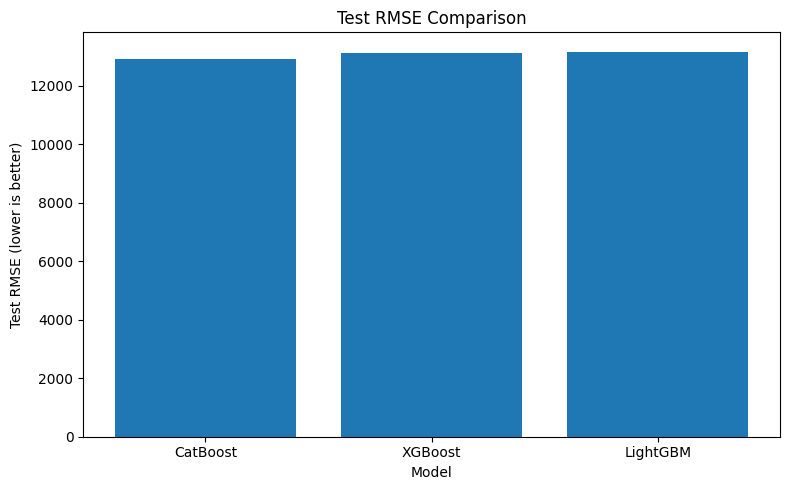

In [58]:
# compare the prediction errors of all three models
plt.figure(figsize=(8, 5))
plt.bar(model_comparison["Model"], model_comparison["Test RMSE"])
plt.title("Test RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("Test RMSE (lower is better)")
plt.tight_layout()
plt.show()

In [60]:
# report the model with the lowest test RMSE
best_row = model_comparison.loc[model_comparison["Test RMSE"].idxmin()]

print("FINAL SUMMARY")
print("-" * 40)
print("Best model by test RMSE:", best_row["Model"])
print("Test RMSE:", round(best_row["Test RMSE"], 3))
print("Test MAE:", round(best_row["Test MAE"], 3))
print("Test R2:", round(best_row["Test R2"], 4))



FINAL SUMMARY
----------------------------------------
Best model by test RMSE: CatBoost
Test RMSE: 12895.739
Test MAE: 9175.335
Test R2: 0.4806
